# 04. EDA sobre `train_70`: perfiles repetidos y duplicados (US-06, sección de Pedro)

**Issue:** #10 (US-06). **Datos:** solo `data/train_70.csv` (5.647 filas). `val_15` y `test_15` no se abren en este notebook (D-006, D-013).

El `01_eda_inicial.ipynb` analizó los perfiles repetidos sobre `Train.csv` completo (8.068 filas). Este notebook repite el análisis **solo sobre la partición de entrenamiento**, como pide el issue, y añade lo que el análisis inicial no medía: qué perfiles aparecen con más de un segmento, cuánto pesan y qué implica para el modelado.

Contenido:

1. Carga y comprobaciones.
2. Perfiles repetidos.
3. Perfiles ambiguos (misma entrada, distinto segmento).
4. Lectura para el modelado.
5. Conclusiones.

La decisión D-009 mantiene las filas con perfiles idénticos: no se eliminan. Este notebook mide cuántas son y cuántas se contradicen.

## 1. Carga y comprobaciones

Se confirma el grano (una fila = un cliente), que `ID` es único y que el objetivo no tiene nulos. La distribución de `Segmentation` es la del split estratificado (D-006): la partición de entrenamiento mantiene las proporciones del conjunto completo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

DATA_PATH = Path("data/train_70.csv")
FIGURES_DIR = Path("reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEGMENT_ORDER = ["A", "B", "C", "D"]
FEATURES = [
    "Gender",
    "Ever_Married",
    "Age",
    "Graduated",
    "Profession",
    "Work_Experience",
    "Spending_Score",
    "Family_Size",
    "Var_1",
]

In [2]:
df = pd.read_csv(DATA_PATH)

assert df["ID"].is_unique, "ID no es único en train_70"
assert df["Segmentation"].notna().all(), "Hay nulos en la variable objetivo"

print(f"Forma: {df.shape[0]:,} filas × {df.shape[1]} columnas".replace(",", "."))

overview = pd.DataFrame(
    {
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().mean() * 100).round(2),
        "valores únicos": df.nunique(dropna=True),
    }
)
display(overview)

target = df["Segmentation"].value_counts().reindex(SEGMENT_ORDER)
display(
    pd.DataFrame(
        {
            "clientes": target,
            "% de train_70": (target / len(df) * 100).round(2),
        }
    )
)

Forma: 5.647 filas × 11 columnas


,tipo,nulos,% nulos,valores únicos
ID,int64,0,0.00,5647
Gender,str,0,0.00,2
Ever_Married,str,99,1.75,2
Age,int64,0,0.00,67
Graduated,str,53,0.94,2
Profession,str,89,1.58,9
Work_Experience,float64,563,9.97,15
Spending_Score,str,0,0.00,3
Family_Size,float64,244,4.32,9
Var_1,str,50,0.89,7


,clientes,% de train_70
Segmentation,,
A,1380,24.44
B,1301,23.04
C,1379,24.42
D,1587,28.10


Las 5.647 filas se agrupan en **5.246 perfiles distintos**: 401 filas comparten los 9 predictores con otra fila. Esa diferencia es la que se analiza a continuación.

## 2. Perfiles repetidos

Un **perfil** es la combinación de los 9 predictores. Si dos clientes tienen el mismo perfil y el mismo segmento, son el mismo tipo de cliente registrado dos veces con distinto `ID`. Si tienen el mismo perfil y **distinto** segmento, los datos se contradicen. Son dos fenómenos distintos y se miden por separado.

In [3]:
grouped = df.groupby(FEATURES, dropna=False)
counts = grouped.size()
n_segments = grouped["Segmentation"].nunique()

repeated = counts[counts > 1]
ambiguous = n_segments[n_segments > 1]

resumen = pd.Series(
    {
        "filas": f"{len(df):,}".replace(",", "."),
        "perfiles distintos": f"{len(counts):,}".replace(",", "."),
        "perfiles con más de una fila": f"{len(repeated):,}".replace(",", "."),
        "filas dentro de esos perfiles": f"{int(repeated.sum()):,}".replace(",", "."),
        "filas sobrantes (filas − perfiles)": f"{len(df) - len(counts):,}".replace(",", "."),
        "perfil más repetido (filas)": f"{int(counts.max())}",
        "% de filas en perfiles repetidos": f"{repeated.sum() / len(df) * 100:.1f} %",
    },
    name="valor",
).to_frame()
display(resumen)

,valor
filas,5.647
perfiles distintos,5.246
perfiles con más de una fila,322
filas dentro de esos perfiles,723
filas sobrantes (filas − perfiles),401
perfil más repetido (filas),6
% de filas en perfiles repetidos,12.8 %


,perfiles,filas
filas por perfil,,
2,265,530
3,40,120
4,13,52
5,3,15
6,1,6


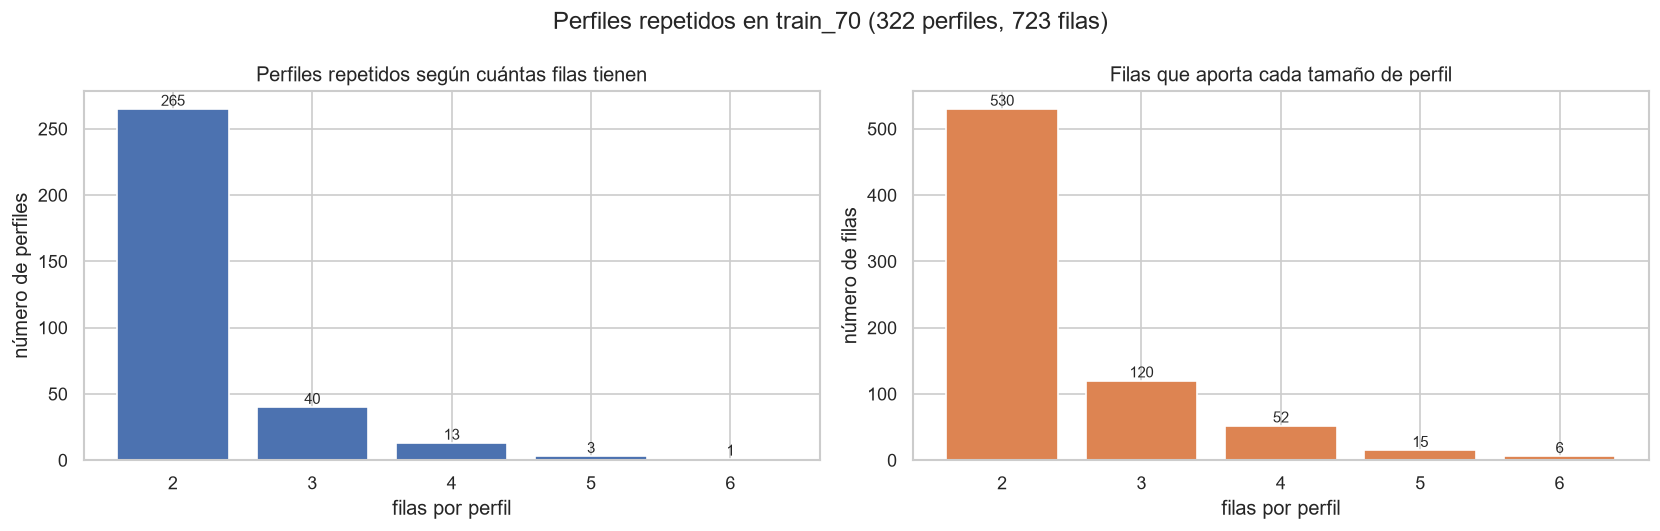

In [4]:
size_table = repeated.value_counts().sort_index()
size_table = pd.DataFrame(
    {"perfiles": size_table, "filas": size_table.index * size_table.values}
)
size_table.index.name = "filas por perfil"
display(size_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(size_table.index.astype(str), size_table["perfiles"], color="#4C72B0")
axes[0].set_title("Perfiles repetidos según cuántas filas tienen")
axes[0].set_xlabel("filas por perfil")
axes[0].set_ylabel("número de perfiles")
for x, value in enumerate(size_table["perfiles"]):
    axes[0].text(x, value, str(value), ha="center", va="bottom", fontsize=9)

axes[1].bar(size_table.index.astype(str), size_table["filas"], color="#DD8452")
axes[1].set_title("Filas que aporta cada tamaño de perfil")
axes[1].set_xlabel("filas por perfil")
axes[1].set_ylabel("número de filas")
for x, value in enumerate(size_table["filas"]):
    axes[1].text(x, value, str(value), ha="center", va="bottom", fontsize=9)

fig.suptitle(f"Perfiles repetidos en train_70 ({len(repeated)} perfiles, {int(repeated.sum())} filas)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_duplicate_profiles.png", bbox_inches="tight")
plt.show()

In [5]:
exactas = int(df.duplicated().sum())
print(f"Filas duplicadas exactas (las 11 columnas): {exactas}")
print(
    "Lo que se repite es el perfil (9 predictores), no el registro: "
    "cada fila tiene su propio ID."
)

Filas duplicadas exactas (las 11 columnas): 0
Lo que se repite es el perfil (9 predictores), no el registro: cada fila tiene su propio ID.


No hay ninguna fila repetida con las 11 columnas: no es un problema de copia y pega. Lo que se repite es el **perfil**, y D-009 decidió conservarlo.

La tabla de evidencia con los 322 perfiles repetidos, su número de filas y su segmento mayoritario se guarda en `reports/duplicates_train_70.csv`.

In [6]:
evidencia = pd.DataFrame(
    {
        "n_filas": repeated,
        "n_segmentos": n_segments[repeated.index],
        "segmento_mayoritario": grouped["Segmentation"].agg(
            lambda s: s.value_counts().idxmax()
        )[repeated.index],
    }
)
evidencia["ambiguo"] = evidencia["n_segmentos"] > 1
evidencia.to_csv("reports/duplicates_train_70.csv")
print(f"Guardadas {len(evidencia)} filas en reports/duplicates_train_70.csv")

Guardadas 322 filas en reports/duplicates_train_70.csv


## 3. Perfiles ambiguos: misma entrada, distinto segmento

Aquí está lo que importa para el modelo. Si dos clientes con los mismos 9 datos están en segmentos distintos, **ninguna regla basada en esos 9 datos puede acertar a los dos**. No es un fallo del modelo: es una contradicción en los datos.

In [7]:
amb_rows = int(counts[ambiguous.index].sum())
resumen_amb = pd.Series(
    {
        "perfiles con más de un segmento": f"{len(ambiguous):,}".replace(",", "."),
        "filas dentro de esos perfiles": f"{amb_rows:,}".replace(",", "."),
        "% de filas de train_70": f"{amb_rows / len(df) * 100:.1f} %",
        "máximo de filas en un perfil ambiguo": f"{int(counts[ambiguous.index].max())}",
    },
    name="valor",
).to_frame()
display(resumen_amb)

,valor
perfiles con más de un segmento,158
filas dentro de esos perfiles,365
% de filas de train_70,6.5 %
máximo de filas en un perfil ambiguo,5


In [8]:
# Ejemplo reproducible: un perfil con dos filas y dos segmentos distintos
profile_id = grouped.ngroup()
profile_stats = pd.DataFrame(
    {
        "n_filas": df.groupby(profile_id)["ID"].size(),
        "n_segmentos": df.groupby(profile_id)["Segmentation"].nunique(),
    }
)
example_id = profile_stats.query("n_filas == 2 and n_segmentos > 1").index[0]

print(
    f"Perfil {example_id}: {profile_stats.loc[example_id, 'n_filas']} filas, "
    f"{profile_stats.loc[example_id, 'n_segmentos']} segmentos distintos"
)
print("Mismos 9 predictores, dos segmentos:")
display(df.loc[profile_id == example_id, FEATURES + ["Segmentation"]])

Perfil 57: 2 filas, 2 segmentos distintos
Mismos 9 predictores, dos segmentos:


,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
753,Female,No,20,No,Doctor,NaN,Low,4.0,Cat_6,D
1459,Female,No,20,No,Doctor,NaN,Low,4.0,Cat_6,C


In [9]:
combos = (
    grouped["Segmentation"]
    .agg(lambda s: " + ".join(sorted(s.unique())))
    .loc[ambiguous.index]
    .value_counts()
    .to_frame("perfiles")
)
display(combos)

,perfiles
Segmentation,
B + C,55
A + B,30
A + C,22
C + D,20
A + D,11
B + D,9
A + B + C,7
B + C + D,3
A + B + D,1


,A,B,C,D
A,71,38,29,12
B,38,105,65,13
C,29,65,107,23
D,12,13,23,44


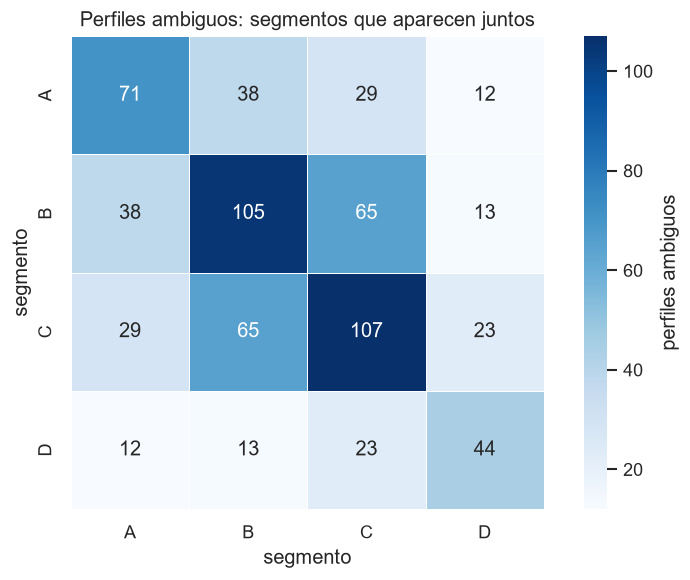

La diagonal cuenta perfiles ambiguos que contienen ese segmento.
Fuera de la diagonal, perfiles que contienen los dos segmentos.


In [10]:
# Coocurrencia: cuántos perfiles ambiguos contienen cada pareja de segmentos
matrix = pd.DataFrame(0, index=SEGMENT_ORDER, columns=SEGMENT_ORDER, dtype=int)
for segments in grouped["Segmentation"].agg(lambda s: tuple(sorted(s.unique()))).loc[ambiguous.index]:
    for first in segments:
        matrix.loc[first, first] += 1
        for second in segments:
            if second != first:
                matrix.loc[first, second] += 1

display(matrix)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "perfiles ambiguos"},
    ax=ax,
)
ax.set_title("Perfiles ambiguos: segmentos que aparecen juntos")
ax.set_xlabel("segmento")
ax.set_ylabel("segmento")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_ambiguous_segment_pairs.png", bbox_inches="tight")
plt.show()

print("La diagonal cuenta perfiles ambiguos que contienen ese segmento.")
print("Fuera de la diagonal, perfiles que contienen los dos segmentos.")

In [11]:
majority = grouped["Segmentation"].agg(lambda s: s.value_counts().idxmax()).loc[ambiguous.index]
display(
    majority.value_counts()
    .reindex(SEGMENT_ORDER, fill_value=0)
    .to_frame("perfiles ambiguos (segmento mayoritario)")
)

per_row = grouped["Segmentation"].transform("nunique")
amb_share = (
    df.assign(ambiguo=per_row > 1)
    .groupby("Segmentation")["ambiguo"]
    .mean()
    .mul(100)
    .round(2)
    .reindex(SEGMENT_ORDER)
    .to_frame("% de filas en perfiles ambiguos")
)
display(amb_share)

,perfiles ambiguos (segmento mayoritario)
Segmentation,
A,40
B,46
C,50
D,22


,% de filas en perfiles ambiguos
Segmentation,
A,5.72
B,8.61
C,9.06
D,3.09


### Qué significa el techo

Las filas de perfiles ambiguos son un **suelo de error**: ningún modelo que use solo estos 9 predictores puede acertarlas todas, como mucho la etiqueta mayoritaria de cada perfil. Se mide a continuación.

Conviene no confundir ese suelo con el techo del modelo. En `train_70` un clasificador que reconociera cada perfil exacto acertaría en torno al 97 %; en datos nuevos la mayoría de los perfiles son nuevos, así que ese 97 % no es alcanzable. Sirve solo para descartar los duplicados como explicación del error: nuestros modelos están en torno al 52–55 %, muy lejos de ese techo.

In [12]:
best = grouped["Segmentation"].agg(lambda s: s.value_counts().max())
unlearnable = len(df) - int(best.sum())
ceiling = int(best.sum()) / len(df)

print(f"Techo en train_70 (perfil → segmento mayoritario): {ceiling:.4f} ({ceiling * 100:.2f} %)")
print(
    f"Filas que ningún modelo con estos 9 predictores puede acertar: "
    f"{unlearnable} ({unlearnable / len(df) * 100:.2f} %)"
)

Techo en train_70 (perfil → segmento mayoritario): 0.9697 (96.97 %)
Filas que ningún modelo con estos 9 predictores puede acertar: 171 (3.03 %)


## 4. Lectura para el modelado

- **D-009 se cumple**: los perfiles repetidos se conservan. Este notebook no elimina ni modifica ninguna fila.
- **B y C son los que más se confunden**: es la pareja que más aparece en los perfiles ambiguos. Anticipa dónde va a fallar el modelo y sirve para la US-14.
- **D aparece en pocos perfiles ambiguos**: su perfil es más distintivo (el más joven y con gasto mayoritariamente bajo), así que es el segmento que mejor se reconoce.
- **El suelo del 3 % no explica el error**: si los modelos aciertan en torno al 55 %, el margen está en la capacidad del modelo y en las variables que faltan, no en los duplicados.
- **Las filas con el mismo perfil pueden caer en particiones distintas**. El split de D-013 es por filas, no por perfil; es una consecuencia conocida del reparto, no una columna que "sepa demasiado". Conviene tenerlo presente al leer la accuracy absoluta en `val_15`.

## 5. Conclusiones

Todas las cifras salen de las celdas anteriores, calculadas sobre `train_70` (5.647 filas).

- **5.246 perfiles distintos** y **401 filas sobrantes**.
- **322 perfiles repetidos** (723 filas); el más repetido aparece **6 veces**.
- **158 perfiles ambiguos** (más de un segmento): **365 filas, el 6,5 %** de la partición.
- **Cero filas duplicadas exactas**: el fenómeno es el perfil, no el registro.
- **171 filas (3,0 %)** son contradictorias: ningún modelo con estos 9 predictores puede acertarlas todas.
- La pareja **B–C** es la que más se repite en los perfiles ambiguos, seguida de A–B y A–C.
- Conclusión para el equipo: los duplicados son un problema **acotado y medido**, no la causa del error de los modelos.

## 6. Checklist de la sección

- [x] Solo `train_70`: `val_15` y `test_15` no se abren.
- [x] Forma, tipos, nulos y distribución del objetivo.
- [x] Perfiles repetidos, filas sobrantes y tamaño de cada perfil.
- [x] Perfiles ambiguos con ejemplo, parejas de segmentos y segmento mayoritario.
- [x] Figuras en `reports/figures/` y tabla de evidencia en `reports/duplicates_train_70.csv`.
- [x] Todas las cifras salen de esta ejecución (`Restart & Run All`).
- [x] Síntesis de las tres secciones: `reports/eda_train70_sintesis.md`.